## Imports

In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..') # path to the root directory
sys.path.append('../..') # path to the root directory
sys.path.append('../../src') # path to the src directory - contains packages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Import Data

In [3]:
# load the database class
import ultrasonic_ml.data.acoustic_datasets as db
from pathlib import Path

# NOTE: make sure this is only open in one notebook at a time, otherwise the database will be locked and you will not be able to access it.
singleroll_filepath = '/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Group/Data/Ultrasound/General Motors/Prismatic Data/091626_singleroll_scan_1mm_multiplexer.sqlite3'
dualroll_filepath = '/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Group/Data/Ultrasound/General Motors/Prismatic Data/092226_dualroll_scan_1mm_multiplexer.sqlite3'

p = Path(dualroll_filepath)

h5_name = p.stem+'.h5'
parent_folder = str(p.parent)


`AcousticDatabase` contains methods to 
* open sqlite file
* convert parameters from dict to hdf5 attr friendly format
* setup groups and datasets for raw and preprocessed data. 
* basic analysis, setup, and filling functions for first break alignment, tof, amplitude, fft, cross correlation, and continuous wavelet transform.
* basic lineplot visulization with matplotlib. This takes the name of a dataset and index as input and allows you to see basic plot
* Does not contain methods for indexing and retrieving data. These will be specific to the type of experiment we have.

`AcousticScanDatabase` inherits from `AcousticDatabase`. 
* Inherits setup and filling functions for different analysis datasets
* You have to write your own indexing and writing methods.
* basic spatial and lineplot visulization with matplotlib. This takes the name of a dataset and index as input and allows you to see basic plot

Funning the setup and writing frunctions only needs to be done one time for each analysius method, and it will be saved in the h5 dataset.

In [4]:
# Initialize the acoustic scan database
database = db.AcousticScanDatabase(parent_folder=parent_folder, 
                                    h5_name=h5_name, 
                                    sqlite_path=dualroll_filepath)

Establishing SQLite connection to database...
Loading h5 parameters...
	Finished.


The first time you initialize `AcousticScanDatabase`, it will create an empty h5 file. You will need to run the setup functions to write metadata, fill raw data, and indexing related parameters

In [21]:
# Run ONCE
# setup and fill the raw data group from sqlite file. 
database.sqlite_to_h5()

Setting up parameters in HDF5 dataset...


Filling raw data: 100%|██████████| 9362/9362 [01:14<00:00, 125.26it/s]


Writing indexed parameters for: ['collection_index', 'time_collected', 'X', 'Z']


4it [00:04,  1.14s/it]

	Finished


In [6]:
# Look at sqlite database structure if you want
database.print_sqlite_schema()

├── parameters
│   ├── gui
│   ├── experiment
│   ├── axis
│   ├── distance
│   ├── transducerFrequency
│   ├── collectionMode
│   ├── pulserType
│   ├── measureTime
│   ├── measureDelay
│   ├── voltageRange
│   ├── autoRange
│   ├── autoRangeEcho
│   ├── waves
│   ├── samples
│   ├── halfCycles
│   ├── multiplexer
│   ├── collectionDirection
│   ├── voltageOffsetForward
│   ├── voltageOffsetReverse
│   ├── gainForward
│   ├── gainReverse
│   ├── picoModule
│   ├── pulseModule
│   ├── rfSwitch
│   ├── t0PulseSwitch
│   ├── t0ReceiveSwitch
│   ├── t1PulseSwitch
│   ├── t1ReceiveSwitch
│   ├── experimentFolder
│   ├── experimentName
│   ├── experimentBaseName
│   ├── saveFormat
│   ├── postAnalysis
│   ├── primaryAxis
│   ├── secondaryAxis
│   ├── primaryAxisRange
│   ├── primaryAxisStep
│   ├── secondaryAxisRange
│   ├── secondaryAxisStep
│   ├── scanInterval
│   ├── numberOfScans
│   ├── pulseInterval
│   ├── experimentTime
│   ├── sweepParams
│   ├── pulserPort
│   ├── scannerPort
│  

In [7]:
# look at parameter setup inside the database.
database.print_parameters()

{   'autoRangeEcho': {   'description': 'Set the oscilloscope to rerun '
                                        'measurements where the voltage range '
                                        'of the wave has significantly '
                                        'changed. This enables the tightest '
                                        'possible voltageRange to be used, '
                                        'increasing the accuracy of low '
                                        'intensity signals without cutting off '
                                        'high intensity ones. For echo '
                                        'measurements, this can add '
                                        'significant overhead (2-3x increase '
                                        'in collection time) for each waveform '
                                        'where the range changes',
                         'value': 'False'},
    'collectionDirection': {   'description': 'for

In [22]:
# look at the h5 database structure
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/indexed_parameters" (4 members)>
|  |--<HDF5 dataset "X": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "Z": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/raw_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<c8"> [1785.66 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]


You can open the h5 file to access the data directly. It is recommended to open the dataset like this to avoid corruption, but you can also define 
`h5_file = database.open_h5()` followed by `h5_file.close()` when you are finished working with it. This is important to avoid corrupting the file.


<KeysViewHDF5 ['config_metadata', 'indexed_parameters', 'raw_data']>
<KeysViewHDF5 ['time_array']>


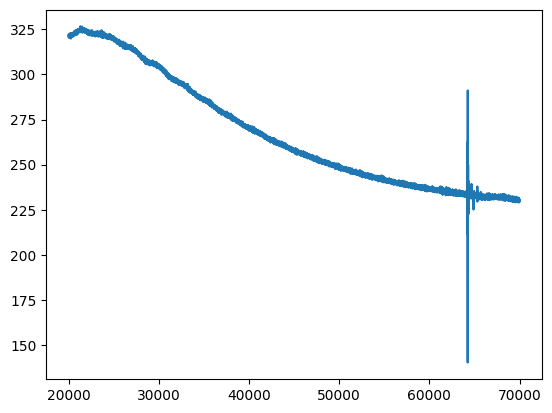

In [24]:
with database.open_h5() as h5_file:
    print(h5_file.keys())
    print(h5_file['raw_data/waveforms'].attrs.keys())
    plt.plot(h5_file['raw_data/waveforms'].attrs['time_array'], h5_file['raw_data/waveforms'][0,0,0])

There is a built in visualization tool for the spatial and temporal data at an index


/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/Notebooks/SAM_examples/../../src/ultrasonic_ml/data/acoustic_datasets.py:1781: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


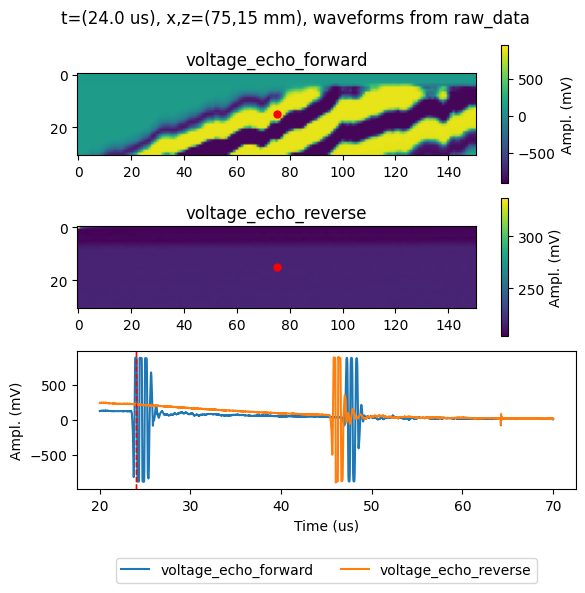

In [ ]:
database.view_img_plot(idx = (75,15,2000), from_group='raw_data', from_dataset='waveforms')

There are functions to visualize the magnitude and phase for complex data. In the case of the hilbert transform, you can visualize the instantaneous amplitude, phase, and frequency of the signal. These can be used to infer the locations of reflective periodic structures, as seen in [article](https://www.sciencedirect.com/science/article/pii/S2352152X22006016)

Phase calculations may take a long time.

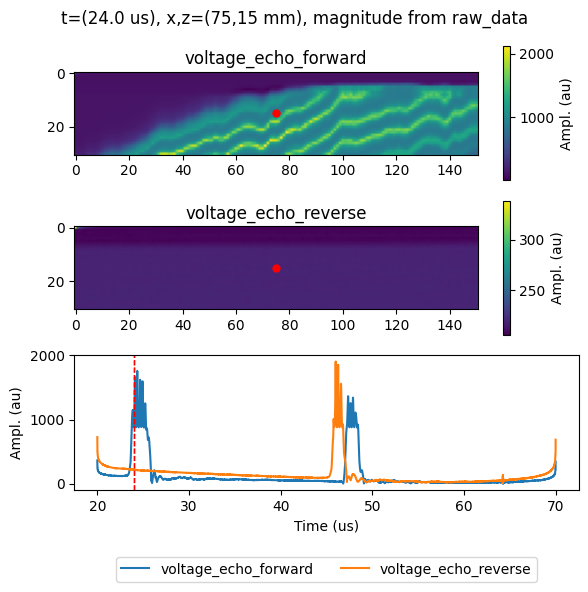

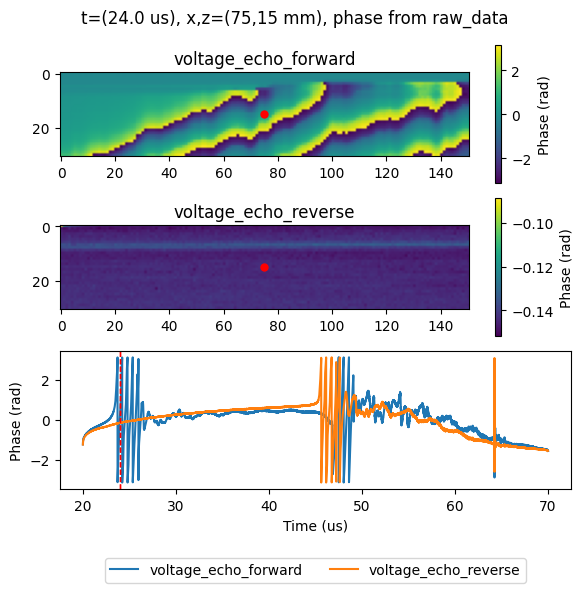

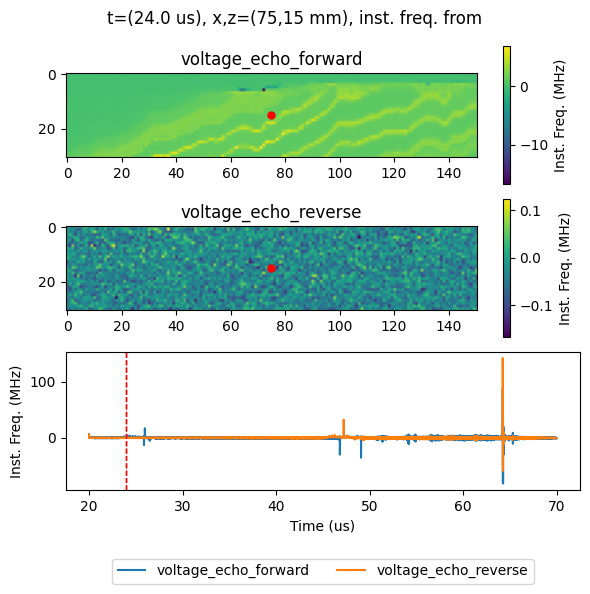

In [35]:
database.view_instantaneous_amplitude_img_plot(idx = (75,15,2000), from_group='raw_data')
database.view_instantaneous_phase_img_plot(idx = (75,15,2000), from_group='raw_data')
database.view_instantaneous_frequency_img_plot(idx = (75,15,2000), from_group='raw_data')

## Preprocessing

Preprocessing includes options to apply a butterworth filter and undo gain.(currently only filter is working)

In [36]:
database.write_preprocessed_data(apply_ungain = False, apply_filter=True, 
                                 lower_fs_coeff = 1/250, upper_fs_coeff = 1/5, filter_order = 3)

Writing preprocessed data: 100%|██████████| 9362/9362 [00:24<00:00, 381.66it/s]


	Finished


In [37]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/indexed_parameters" (4 members)>
|  |--<HDF5 dataset "X": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "Z": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<c8"> [1785.66 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]
|--<HDF5 group "/raw_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<c8"> [1785.66 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]


We can look at the same figures as the raw data section and see how the signal improves.

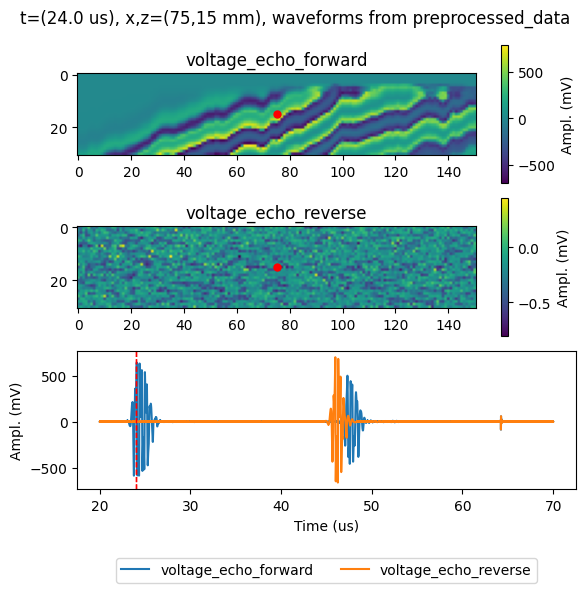

In [ ]:
# TODO: figure out why analytic signals are so different from raw. Is this the case for all data?
database.view_img_plot(idx = (75,15,2000), from_group='preprocessed_data', from_dataset='waveforms')

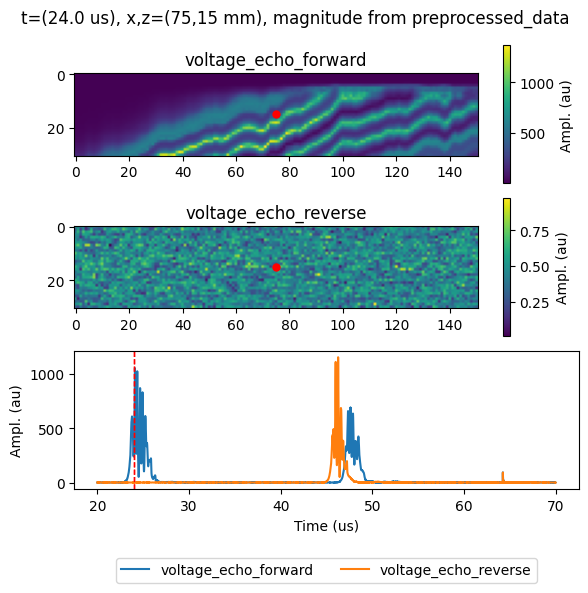

In [5]:
database.view_instantaneous_amplitude_img_plot(idx = (75,15,2000), from_group='preprocessed_data')

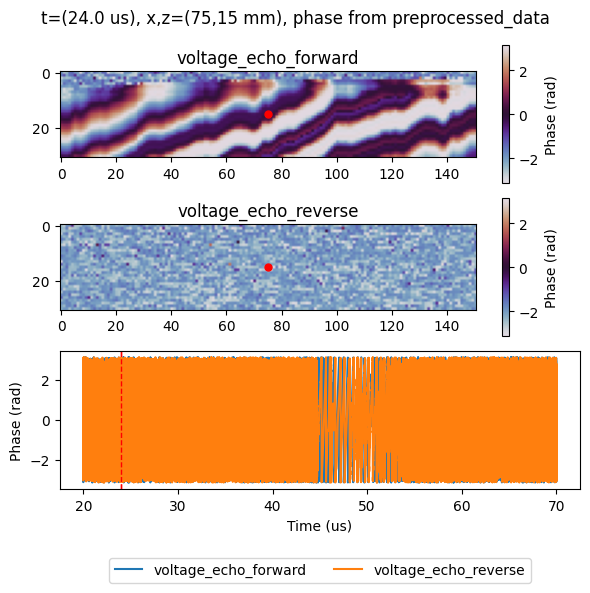

In [6]:
database.view_instantaneous_phase_img_plot(idx = (75,15,2000), from_group='preprocessed_data')

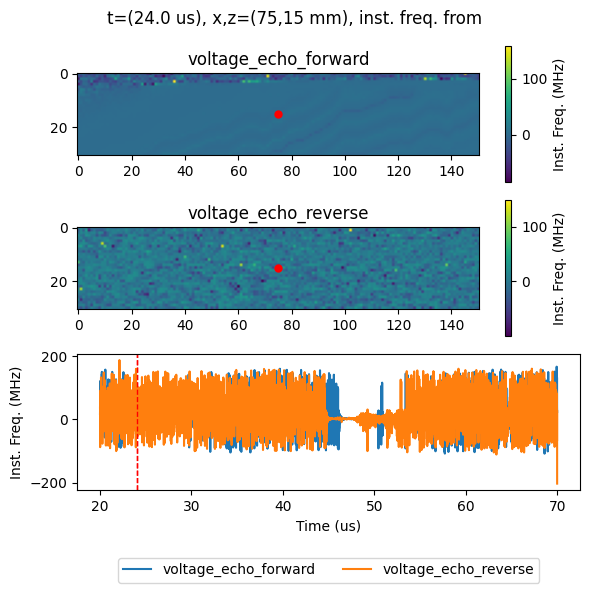

In [7]:
database.view_instantaneous_frequency_img_plot(idx = (75,15,2000), from_group='preprocessed_data')

## Match first break

If we are looking at a scan of a battery, from 2 sides, it would be useful to line up the first break of the waveforms. We can do this and delete any old datasets that we don't need

In [26]:
# Delete exisitng group or dataset if we dont need it anymore.
with database.open_h5() as h5_file:
    del h5_file['first_break_aligned'] # group
    # del h5_file['preprocessed_data/tof'] # dataset

In [27]:
# RUN ONCE
# align forward and reverse waveforms to first break and save to h5.
database.write_first_break_aligned_data(from_group='preprocessed_data')

Aligning first break: 100%|██████████| 9362/9362 [00:11<00:00, 839.82it/s] 

	Finished


In [28]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<c8"> [985.33 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (4 members)>
|  |--<HDF5 dataset "X": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "Z": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<c8"> [1785.66 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 25000), type "<f4"> [892.83 MB]
|--<HDF5 group "/raw_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type

In [29]:
with database.open_h5() as h5_file:
    print(h5_file['first_break_aligned/waveforms'].attrs['rollbacks'])

[    0 11205]


/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/Notebooks/SAM_examples/../../src/ultrasonic_ml/data/acoustic_datasets.py:1329: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


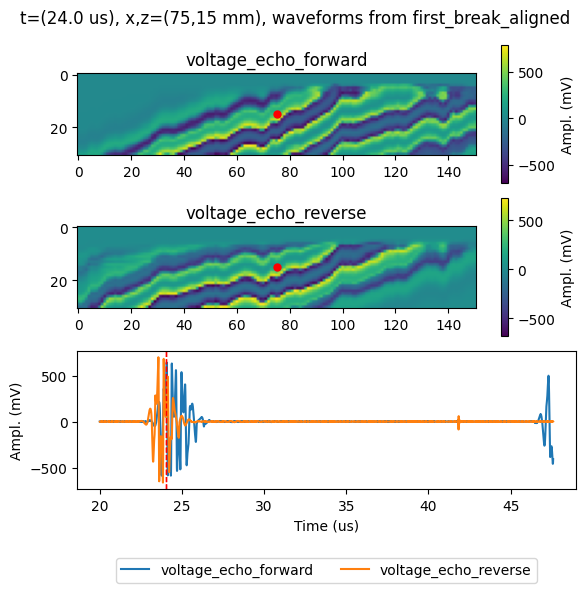

In [30]:
# check that alignment is right. You can look at waveforms or hilbert.
database.view_img_plot(idx = (75,15,2000), from_group='first_break_aligned', from_dataset='waveforms')

/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/Notebooks/SAM_examples/../../src/ultrasonic_ml/data/acoustic_datasets.py:1359: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


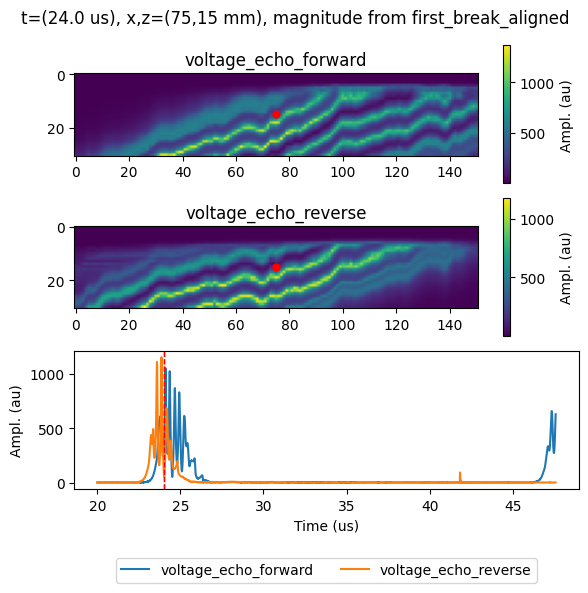

In [39]:
database.view_instantaneous_amplitude_img_plot(idx = (75,15,2000), from_group='first_break_aligned')

/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/Notebooks/SAM_examples/../../src/ultrasonic_ml/data/acoustic_datasets.py:36: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  The path to the HDF5 file.


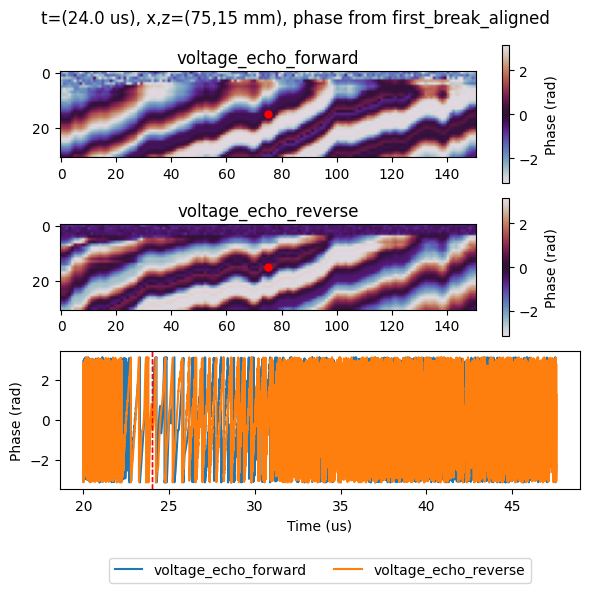

In [40]:
database.view_instantaneous_phase_img_plot(idx = (75,15,2000), from_group='first_break_aligned')

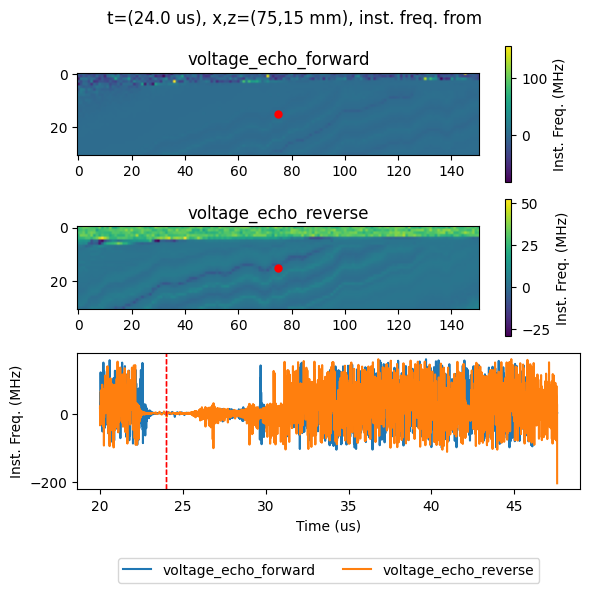

In [42]:
database.view_instantaneous_frequency_img_plot(idx = (75,15,2000), from_group='first_break_aligned')

## Basic ToF and Hilbert Amplitude

We can get some basic information from the preprocessed data and display it. We only need to run these functions ONCE.

* The time of flight is calculated as the fraction threshold of the maximum of the hilbert window, within a cropped area.
* The amplitude is the maximum of the hilbert window, within a cropped area.

In [59]:
database.write_tof_data(from_group='first_break_aligned', threshold_fraction=0.1, crop=(0,7500))

Calculating ToF: 100%|██████████| 9362/9362 [00:01<00:00, 4810.50it/s]

	Finished


In [60]:
database.write_amplitude_data(from_group='first_break_aligned', crop=(0,7500))

Calculating Amplitude: 100%|██████████| 9362/9362 [00:01<00:00, 8393.63it/s]

	Finished


In [46]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (4 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<c8"> [985.33 MB]
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (4 members)>
|  |--<HDF5 dataset "X": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "Z": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 25000), type "<c8"> [1785.66 MB]
|  |--<HDF5 dataset "waveforms": shape (2,

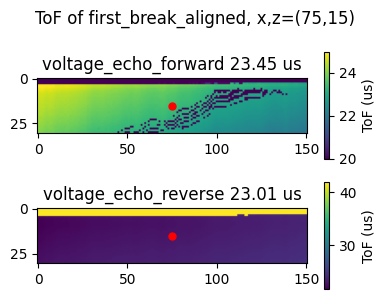

In [58]:
database.img_tof(idx=(75,15), from_group='first_break_aligned')

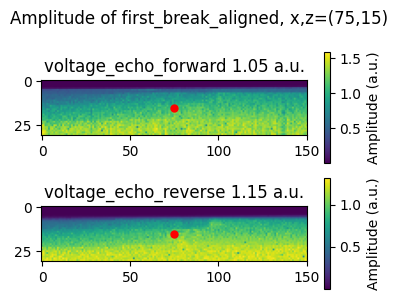

In [57]:
database.img_amplitude(idx=(75,15), from_group='first_break_aligned')

## Calculate FFT

In [7]:
# RUN ONCE
# align forward and reverse waveforms to first break and save to h5.
database.write_fft_data(from_group='first_break_aligned')

Computing FFT: 100%|██████████| 9362/9362 [00:08<00:00, 1114.77it/s]


	Finished


In [9]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (6 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "fft_data": shape (2, 151, 31, 6898), type "<c8"> [492.70 MB]
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<c8"> [985.33 MB]
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "x_corr": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (4 members)>
|  |--<HDF5 dataset "X": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "Z": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 gr

<Figure size 640x480 with 0 Axes>

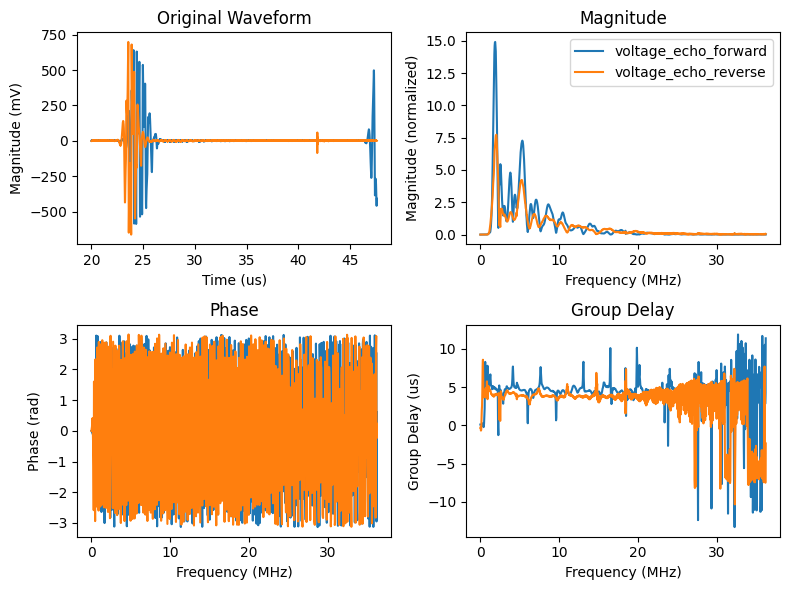

In [8]:
database.view_fft_plots(idx=(75,15), crop=[0, 1000], from_group='first_break_aligned')

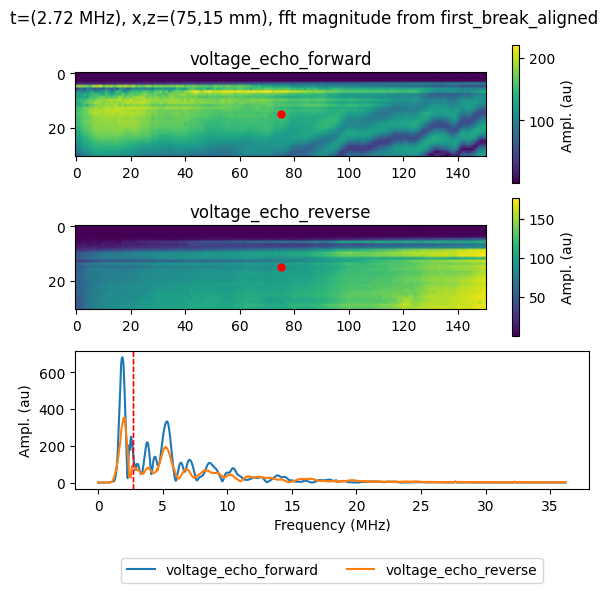

In [22]:
database.view_fft_amplitude_img_plot(idx=(75,15,75), crop=[0, 1000], from_group='first_break_aligned')

<string>:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


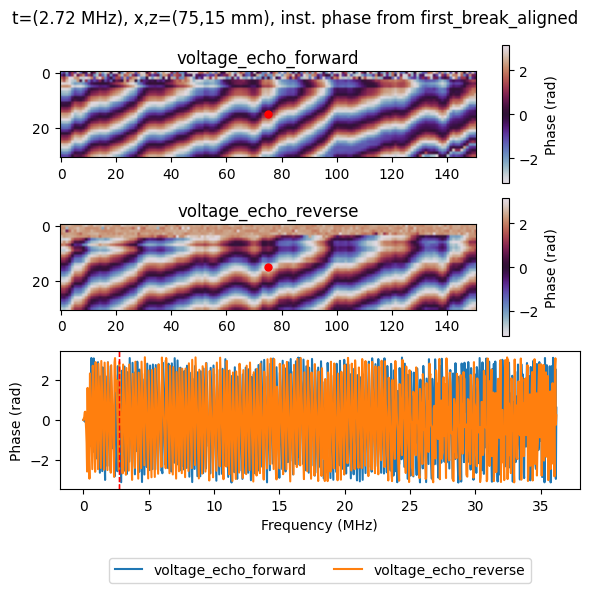

In [26]:
database.view_fft_phase_img_plot(idx=(75,15,75), crop=[0, 1000], from_group='first_break_aligned', unwrap=False)

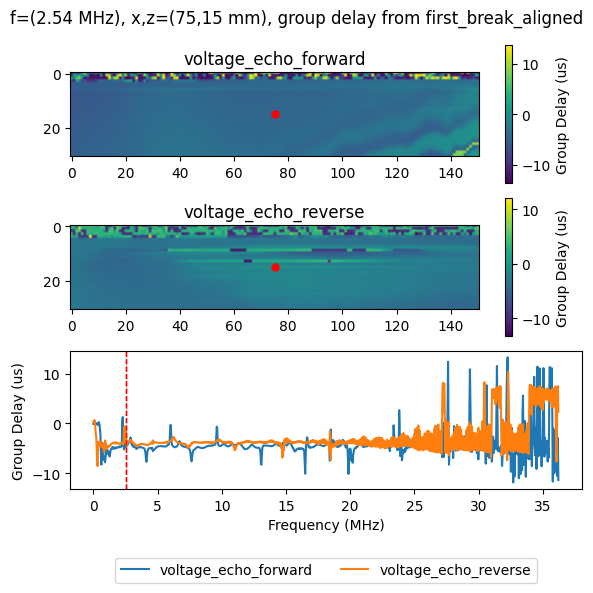

In [32]:
database.view_fft_gdelay_img_plot(idx=(75,15,70), crop=[0, 1000], from_group='first_break_aligned')

## Try correlation with mother waveform

### Cross correlation

Sliding dot product of a waveform with another waveform. Convolution is with the flipped waveform, and is alternative implementation. (#TODO: implement)
[Difference here.](https://towardsdatascience.com/convolution-vs-correlation-af868b6b4fb5/)

We can try cross-correlation using a mother waveform, such as the wave through the coupling fluid. The write_ function requires a path to the sqlite database for the mother waveform.

We can also try cross correlation using a reference waveform from a different SoC, or between batteries made of different electrode compositions. This is particularly useful for noisy datasets.

During setup, the mother wavelet will be interpolated to match the timestep of the current data.

In [68]:
water_sqlite_file = '/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Sam Amsterdam/acoustic scan data/tomography_testing/example_data/SA_tomography_test_water.sqlite3'

database.write_xcorrelation_data(mother_db_path=water_sqlite_file, from_group='first_break_aligned', mode='same')

Establishing SQLite connection to database...


Calculating Cross-correlation: 100%|██████████| 9362/9362 [00:08<00:00, 1047.17it/s]

	Finished


/Users/xz498/Library/CloudStorage/OneDrive-DrexelUniversity/Chang Lab - Documents/General/Individual/Xinqiao Zhang/data_analysis/ultrasonic_ml/Notebooks/SAM_examples/../../src/ultrasonic_ml/data/acoustic_datasets.py:1125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


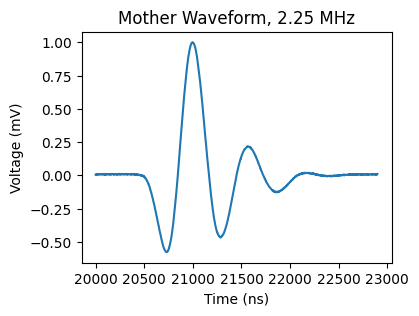

In [62]:
# Look at mother waveform:
database.view_mother_waveform(from_group='first_break_aligned')

In [66]:
with database.open_h5() as h5_file:
    h5_file['first_break_aligned/x_corr'].attrs['time_array'] = h5_file['first_break_aligned/waveforms'].attrs['time_array']
    print(h5_file['first_break_aligned/x_corr'].attrs.keys())

<KeysViewHDF5 ['mode', 'mother_waveform', 'mother_time_array', 'mother_frequency', 'time_array']>


In [71]:
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (5 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<c8"> [985.33 MB]
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "x_corr": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (4 members)>
|  |--<HDF5 dataset "X": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "Z": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151

<string>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


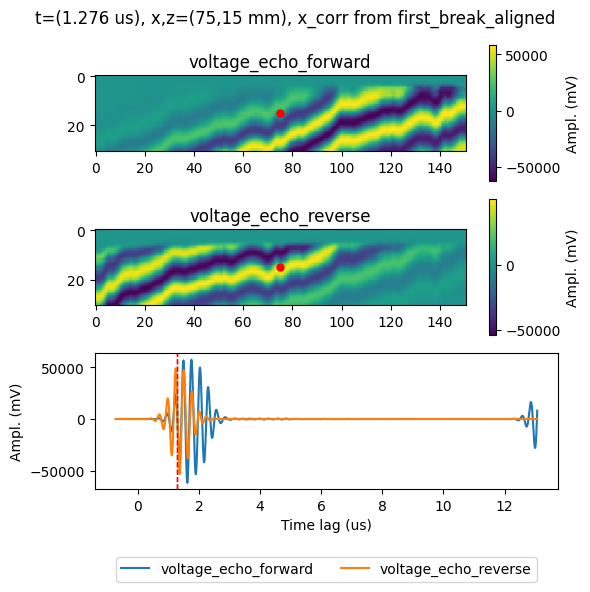

In [72]:
# x_correlation data is now written to the h5 file. Let's look at the data.
database.view_img_correlation(idx = (75,15,2000), from_group='first_break_aligned', from_dataset='x_corr')

In [6]:
# look at the h5 database structure now
database.print_schema()

<HDF5 file "092226_dualroll_scan_1mm_multiplexer.h5" (mode r+)>
|--<HDF5 dataset "config_metadata": shape (), type "|O"> [0.00 MB]
|--<HDF5 group "/first_break_aligned" (5 members)>
|  |--<HDF5 dataset "amplitude": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "hilbert": shape (2, 151, 31, 13795), type "<c8"> [985.33 MB]
|  |--<HDF5 dataset "tof": shape (2, 151, 31), type "<f4"> [0.04 MB]
|  |--<HDF5 dataset "waveforms": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|  |--<HDF5 dataset "x_corr": shape (2, 151, 31, 13795), type "<f4"> [492.66 MB]
|--<HDF5 group "/indexed_parameters" (4 members)>
|  |--<HDF5 dataset "X": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "Z": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "collection_index": shape (151, 31), type "<f4"> [0.02 MB]
|  |--<HDF5 dataset "time_collected": shape (151, 31), type "<f4"> [0.02 MB]
|--<HDF5 group "/preprocessed_data" (2 members)>
|  |--<HDF5 dataset "hilbert": shape (2, 151

## Wavelet analysis

Continuous wavelet transform essentially takes different frequencies of a wavelet (ie, morlet, complex morlet, mexican hat) and perform a sliding dot product across the waveform. The resulting scaleogram reveals information about the frequency/time relationship

You can try cropping the fft to see what frequencies have the most signal. These are likely where we will see the most information. This frequencies in this cropped region can be used to decide what frequencies will be used in the wavelet transform.

<Figure size 640x480 with 0 Axes>

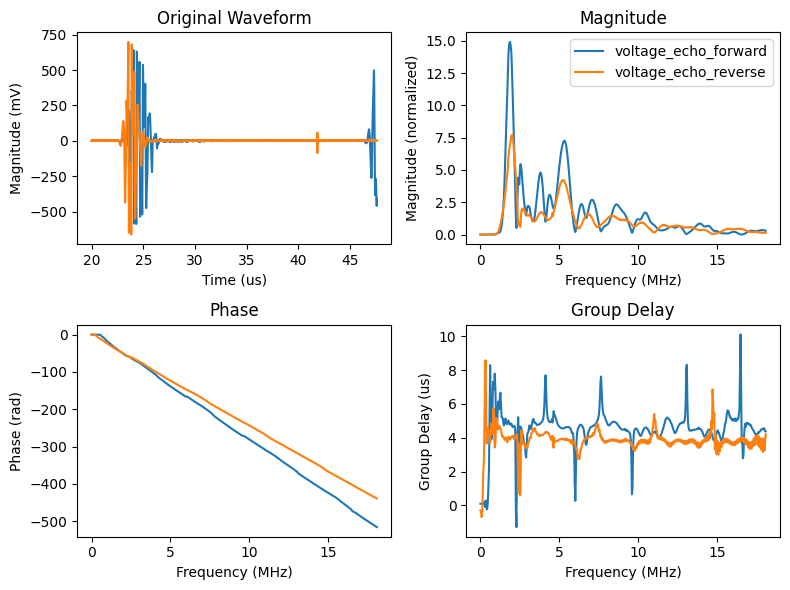

In [150]:
database.view_fft_plots(idx=(75,15), crop=[0, 500], from_group='first_break_aligned', unwrap=True)

When choosing the type of wavelet and scales to use, consider some of the following:
* the complex morlet has the name `'cmorB-C'` where `B` is the width of the band, which `C` is the input freq. 
* You should choose a band where the fwhm of the wavelet at your transducer's frequency is not too much larger or smaller the your freature size in your waveform
* output might look something like below, and will likely take a vevry long time:
```
cmor2.0-1.0 at 450000.00 MHz, width at fwhm: 5.23 us
cmor2.0-1.0 at 2250000.00 MHz, width at fwhm: 1.05 us
cmor2.0-1.0 at 22500000.00 MHz, width at fwhm: 0.10 us
Periods in record (lowest f, highest f): 12.4155 620.7750000000001
Calculating CWT:   5%|▌         | 488/9362 [01:05<19:57,  7.41it/s]
```

In [276]:
database.write_cwt_data(from_group='first_break_aligned', wavelet_name='cmor2.0-1.0', n_scales=100)

cmor2.0-1.0 at 450000.00 MHz, width at fwhm: 5.23 us
cmor2.0-1.0 at 2250000.00 MHz, width at fwhm: 1.05 us
cmor2.0-1.0 at 22500000.00 MHz, width at fwhm: 0.10 us
Periods in record (lowest f, highest f): 12.4155 620.7750000000001


Calculating CWT:   5%|▌         | 488/9362 [01:05<19:57,  7.41it/s]


KeyboardInterrupt: 

In [254]:
with database.open_h5() as h5_file:
    test = h5_file['first_break_aligned/waveforms'][1,75,15][:10000]
    time = h5_file['first_break_aligned/waveforms'].attrs['time_array'][:10000]

In [255]:
wavelet = 'cmor0.5-1.0' # we can make B a little smaller since we dont care ab frequency as much # TODO: test several B to whatever matches water pulse the best
n_scales=150

c_freq = database.parameters['transducerFrequency']['value']*1e6
sampling_period = database.parameters['dt']['value'] # (s)

freqs_of_interest = np.geomspace(c_freq/5, c_freq*10, num=150) #  in Hz
central_freq = pywt.central_frequency(wavelet)      # normalized center freq of the wavelet
scales = central_freq / sampling_period / freqs_of_interest      # scale = f_c * fs / f_target
period_samples = scales / central_freq        # wavelet period in samples
print('periods in record (lowest f, highest f):',
      len(test) / period_samples.max(), len(test) / period_samples.min())

periods in record (lowest f, highest f): 9.0 450.0000000000001


In [256]:

cwt_mat, freqs_out = pywt.cwt(test, scales, wavelet, sampling_period=sampling_period, method='fft')


In [257]:
# from matplotlib.colors import LogNorm

# to_plot = np.abs(cwt_mat)
# magnitude = np.ma.masked_less_equal(to_plot, 0)

# fig, axs = plt.subplots()
# pcm = axs.pcolormesh(
#     time/1e3, freqs_out, magnitude,
#     norm=LogNorm(vmin=magnitude.min(), vmax=magnitude.max())
# )
# axs.axhline(2.25e6, color='red', linestyle='--', linewidth=1.5, label='2.25 MHz')
# axs.legend(
#     [axs.lines[-1]],
#     ['Transducer frequency (2.25 MHz)'],
#     loc='upper center',
#     bbox_to_anchor=(0.5, -0.12)
# )
# axs.set_yscale("log")
# axs.set_xlabel("Time (us)")
# axs.set_ylabel("Frequency (Hz)")
# axs.set_title("Continuous Wavelet Transform (Scaleogram)")
# fig.colorbar(pcm, ax=axs, label="Magnitude (log scale)")
# plt.tight_layout()


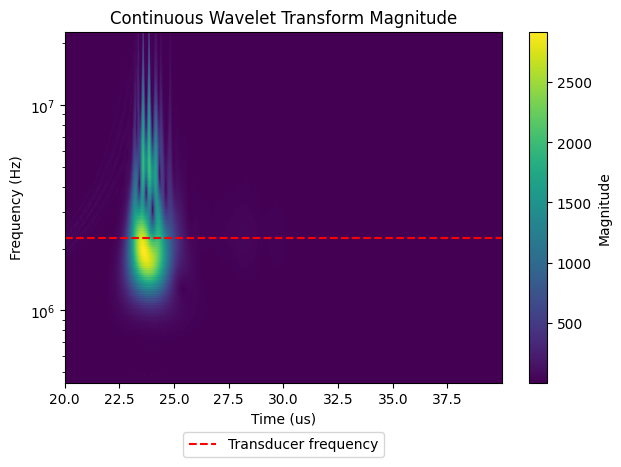

In [ ]:
to_plot = np.abs(cwt_mat)

fig, axs = plt.subplots()
pcm = axs.pcolormesh(
    time / 1e3, freqs_out, to_plot,
    cmap="viridis"
)
axs.axhline(c_freq, color="red", linestyle="--", linewidth=1.5, label="Transducer frequency")
axs.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
axs.set_xlabel("Time (us)")
axs.set_yscale("log")
axs.set_ylabel("Frequency (Hz)")
axs.set_title("Continuous Wavelet Transform Magnitude")
fig.colorbar(pcm, ax=axs, label="Magnitude")
plt.tight_layout()


In [263]:
np.angle(cwt_mat).shape

(150, 10000)

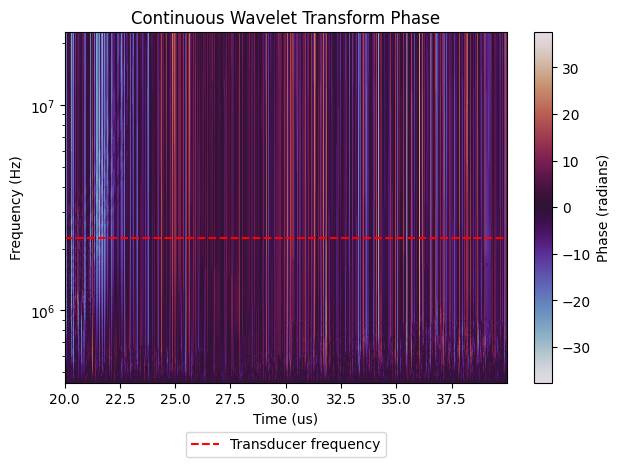

In [266]:
to_plot = np.unwrap(np.angle(cwt_mat), axis=0)

fig, axs = plt.subplots()
pcm = axs.pcolormesh(
    time / 1e3, freqs_out, to_plot,
    cmap="twilight"
)
axs.axhline(c_freq, color="red", linestyle="--", linewidth=1.5, label="Transducer frequency")
axs.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12))
axs.set_xlabel("Time (us)")
axs.set_yscale("log")
axs.set_ylabel("Frequency (Hz)")
axs.set_title("Continuous Wavelet Transform Phase")
fig.colorbar(pcm, ax=axs, label="Phase (radians)")
plt.tight_layout()


#### There are some things to look out for:

* The "exponential" looking lines leading behind the peaks are likely an artifact. It forms as the tail of the wavelet gradually moves over the signal during convolution.
* Be wary of edge effects at the beginning and end of the time sequence. The severity will depend on the band size of the wavelet you use. 
* If there are "streaks" going far into the high frequency areas, these can indicate sharp features such as discontinuities or noise. These can be cause by flat topped peaks from voltage range cut off or noise. It is best to retake these waveforms with proper voltage range set. 

## Interactive visualizer

We can launch the interactive visualizer on a web browser. Interact on the browser, then press enter in the python prompt when complete

In [91]:
from ultrasonic_ml.viz import acoustic_viewers as viz

viz.AcousticScanViewerFFT.launch(db=database, from_group='preprocessed_data', aspect_ratio=6, crop = [0,1500])

Opening FFT datasets from group: preprocessed_data
Launching server at http://localhost:63911


Invoked as spatial_renderer(current_y=13655, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as dynamic_operation(current_y=13655, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as spatial_renderer(current_y=13655, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as dynamic_operation(current_y=13655, current_x=75, current_z=15, dataset='tof', x=75, y=15)


Traceback (most recent call last):
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/plotting/util.py", line 319, in get_plot_frame
    return map_obj[key]
           ~~~~~~~^^^^^
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 1368, in __getitem__
    val = self._execute_callback(*tuple_key)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 1118, in _execute_callback
    retval = self.callback(*args, **kwargs)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 675, in __call__
    ret = self.callable(*args, **kwargs)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/util/__init__.py", line 1135, in dynamic_operation
    key, obj = resolve(key, kwargs)
               ~~~~~~~^^^^^

Invoked as spatial_renderer(current_y=2274, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as dynamic_operation(current_y=2274, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as spatial_renderer(current_y=2274, current_x=75, current_z=15, dataset='tof', x=75, y=15)
Invoked as dynamic_operation(current_y=2274, current_x=75, current_z=15, dataset='tof', x=75, y=15)


Traceback (most recent call last):
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/plotting/util.py", line 319, in get_plot_frame
    return map_obj[key]
           ~~~~~~~^^^^^
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 1368, in __getitem__
    val = self._execute_callback(*tuple_key)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 1118, in _execute_callback
    retval = self.callback(*args, **kwargs)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/spaces.py", line 675, in __call__
    ret = self.callable(*args, **kwargs)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/util/__init__.py", line 1135, in dynamic_operation
    key, obj = resolve(key, kwargs)
               ~~~~~~~^^^^^

In [5]:
from ultrasonic_ml.viz import acoustic_viewers as viz

viz.AcousticScanViewer.launch(db=database, from_group='preprocessed_data', aspect_ratio=6, crop = [0,1500])

Launching server at http://localhost:50947


/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/util/__init__.py:1065: ComplexWarning: Casting complex values to real discards the imaginary part
  fv = float(v)
/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/util/__init__.py:1065: ComplexWarning: Casting complex values to real discards the imaginary part
  fv = float(v)
/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/util/__init__.py:1065: ComplexWarning: Casting complex values to real discards the imaginary part
  fv = float(v)
/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/util/__init__.py:1065: ComplexWarning: Casting complex values to real discards the imaginary part
  fv = float(v)
/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/holoviews/core/util/__init__.py:1065: ComplexWarning: Casting complex values to

Traceback (most recent call last):
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/panel/io/handlers.py", line 366, in run_app
    handler._func(doc)
    ~~~~~~~~~~~~~^^^^^
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/panel/io/application.py", line 83, in _eval_panel
    doc = as_panel(panel)._modify_doc(server_id, title, doc, location)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/panel/viewable.py", line 363, in _modify_doc
    return self.server_doc(doc, title, location) # type: ignore
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/panel/viewable.py", line 1080, in server_doc
    model = self.get_root(doc)
  File "/Users/xz498/Applications/anaconda3/envs/ultrasound/lib/python3.14/site-packages/panel/layout/base.py", line 386, in get_root
    root = super().get_root(do